## 1. Setup & Instalasi
Menginstal library NeuralForecast.

In [7]:
!pip install -q neuralforecast scipy

## 2. Load Data & Konfigurasi
Sama persis dengan konfigurasi v1 untuk menjamin apple-to-apple comparison.

In [8]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.stats import norm

# Load Data
dl_path = '/kaggle/input/datasets/ferastoro/ai-stocks-crypto-and-ihsg/data/clean/dataset_deep_learning.csv'
df = pd.read_csv(dl_path)

# --- MERGE TVP-VAR DYNAMIC FEATURES ---
tvp_path = '/kaggle/input/datasets/ferastoro/ai-stocks-crypto-and-ihsg/data/clean/tvp_var_dynamic_features.csv'
if not os.path.exists(tvp_path):
    tvp_path = 'data/clean/tvp_var_dynamic_features.csv'
df_tvp = pd.read_csv(tvp_path)
df_tvp['Date'] = pd.to_datetime(df_tvp['Date'])
df['Date'] = pd.to_datetime(df['Date'])
df = pd.merge(df, df_tvp, on='Date', how='left')
tvp_cols = [c for c in df_tvp.columns if c != 'Date']
df[tvp_cols] = df[tvp_cols].ffill()
df.dropna(inplace=True)
df.reset_index(drop=True, inplace=True)
print(f'Baris setelah merge TVP-VAR: {len(df)}')
# Target
df['volatility_btc_idr'] = df['ret_crypto_btc_idr_indodax']**2

# Format NeuralForecast
nf_df = pd.DataFrame({
    'unique_id': 'BTC_IDR',
    'ds': pd.date_range(start='2020-01-01', periods=len(df), freq='D'), 
    'y': df['volatility_btc_idr'].values
})

# Menambahkan Exogenous Features sebagai historis
exog_cols = [
    'ret_saham_nvda', 'ret_saham_msft', 'ret_saham_tsla', 'ret_saham_googl', 'ret_saham_meta',
    'ret_crypto_btc_usd', 'ret_crypto_eth_usd', 'crypto_btc_usd_weekend_return',
    'spillover_ai_to_btcidr', 'net_spill_saham_nvda', 'net_spill_saham_tsla', 'tvp_tsi',
    'gap_days', 'is_monday', 'is_ihsg_holiday',
]
print(f"\nexog_cols final V2 (harus identik dengan V1): {exog_cols}")
assert all(c in df.columns for c in exog_cols), "Ada kolom exog yang hilang setelah merge!"

for col in exog_cols:
    nf_df[col] = df[col].values

# Tambahan untuk mapping tanggal asli ke laporan evaluasi
nf_df['real_date'] = df['Date'].values

# Split Train/Val/Test (SAMA PERSIS DENGAN V1)
N = len(nf_df)
n_test = int(N * 0.20)
n_val = int(N * 0.10)
n_train = N - n_test - n_val

df_train = nf_df.iloc[:n_train].copy()
df_val = nf_df.iloc[n_train:n_train+n_val].copy()
df_test = nf_df.iloc[n_train+n_val:].copy()

print(f"Total data: {N} | Train: {len(df_train)} | Val: {len(df_val)} | Test: {len(df_test)}")


Baris setelah merge TVP-VAR: 1676

exog_cols final V2 (harus identik dengan V1): ['ret_saham_nvda', 'ret_saham_msft', 'ret_saham_tsla', 'ret_saham_googl', 'ret_saham_meta', 'ret_crypto_btc_usd', 'ret_crypto_eth_usd', 'crypto_btc_usd_weekend_return', 'spillover_ai_to_btcidr', 'net_spill_saham_nvda', 'net_spill_saham_tsla', 'tvp_tsi', 'gap_days', 'is_monday', 'is_ihsg_holiday']
Total data: 1676 | Train: 1174 | Val: 167 | Test: 335


## 3. Inisialisasi 4 Model Baru (TiDE, NBEATSx, TSMixerx, KAN)
DeepAR dicoret karena tidak mendukung *historical exogenous*. Ditambahkan KAN (Kolmogorov-Arnold Network) sebagai model terbaru.

In [9]:
from neuralforecast import NeuralForecast
from neuralforecast.models import TiDE, NBEATSx, TSMixerx, KAN
import torch

H = 10
INPUT_SIZE = 30
MAX_STEPS = 500

models_v2 = [
    TiDE(
        h=H, input_size=INPUT_SIZE, hist_exog_list=exog_cols, 
        max_steps=MAX_STEPS, val_check_steps=50, random_seed=42, 
        scaler_type='standard', devices=1
    ),
    NBEATSx(
        h=H, input_size=INPUT_SIZE, hist_exog_list=exog_cols, 
        max_steps=MAX_STEPS, val_check_steps=50, random_seed=42, 
        scaler_type='standard', devices=1
    ),
    TSMixerx(
        h=H, input_size=INPUT_SIZE, hist_exog_list=exog_cols, 
        n_series=1, # Wajib untuk TSMixerx 
        max_steps=MAX_STEPS, val_check_steps=50, random_seed=42, 
        scaler_type='standard', devices=1
    ),
    KAN(
        h=H, input_size=INPUT_SIZE, hist_exog_list=exog_cols, 
        max_steps=MAX_STEPS, val_check_steps=50, random_seed=42, 
        scaler_type='standard', devices=1
    )
]

nf_v2 = NeuralForecast(models=models_v2, freq='D')
print("Model V2 (TiDE, NBEATSx, TSMixerx, KAN) berhasil diinisialisasi.")


Seed set to 42
Seed set to 42
Seed set to 42
Seed set to 42


Model V2 (TiDE, NBEATSx, TSMixerx, KAN) berhasil diinisialisasi.


## 4. Training (Cross-Validation)

In [10]:
print("Memulai cross-validation untuk model V2...")
cv_df_v2 = nf_v2.cross_validation(df=nf_df.drop(columns=["real_date"]), val_size=n_test, test_size=n_test, n_windows=None)
cv_df_v2 = cv_df_v2.reset_index(drop=True)

# Map real_date kembali ke hasil evaluasi
if "real_date" not in cv_df_v2.columns:
    cv_df_v2 = pd.merge(cv_df_v2, nf_df[["unique_id", "ds", "real_date"]], on=["unique_id", "ds"], how="left")


Memulai cross-validation untuk model V2...


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]

   | Name                 | Type          | Params | Mode 
----------------------------------------------------------------
0  | loss                 | MAE           | 0      | train
1  | hist_cat_embeddings  | ModuleList    | 0      | train
2  | futr_cat_embeddings  | ModuleList    | 0      | train
3  | stat_cat_embeddings  | ModuleList    | 0      | train
4  | padder_train         | ConstantPad1d | 0      | train
5  | scaler               | TemporalNorm  | 0      | train
6  | hist_exog_projection | MLPResidual   | 10.3 K | train
7  | dense_encoder        | Sequential    | 418 K  | train
8  | dense_decoder        | Sequential    | 591 K  | train
9  | temporal_decoder     | MLPResidual   | 4.4 K  | train
10 | global_skip          | Linear        | 310    | train
----------------------------------------------------------------
1.0 M     Trainable params
0         

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

... (52 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_steps=500` reached.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]


Predicting: |          | 0/? [00:00<?, ?it/s]

## 5. Gabung dengan Hasil V1 (TFT, LSTM, NHITS)

In [11]:
v1_path = '/kaggle/input/notebooks/ferastoro/deep-learning-spillover-v1/results/CV_Predictions.csv'
try:
    cv_df_v1 = pd.read_csv(v1_path)
    
    # TAMBAHKAN BARIS INI UNTUK MENYAMAKAN TIPE DATA TANGGAL
    cv_df_v1['ds'] = pd.to_datetime(cv_df_v1['ds'])
    
    merged_cv = pd.merge(cv_df_v2, cv_df_v1[['unique_id', 'ds', 'TFT', 'LSTM', 'NHITS']], 
                         on=['unique_id', 'ds'], how='inner')
    print("Berhasil menggabungkan hasil V1 dan V2.")
except FileNotFoundError:
    print(f"File V1 tidak ditemukan di {v1_path}. Coba sesuaikan path-nya.")
    merged_cv = cv_df_v2.copy()


Berhasil menggabungkan hasil V1 dan V2.


## 6. Evaluasi Metrik Gabungan, Baseline & Uji Diebold-Mariano

In [12]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from scipy.stats import norm
import numpy as np
import pandas as pd

# 1. Bangun kolom h_step
merged_cv_sorted = merged_cv.sort_values(["cutoff", "ds"]).copy()
merged_cv_sorted["h_step"] = merged_cv_sorted.groupby(["unique_id", "cutoff"]).cumcount() + 1

# Pastikan ds bertipe datetime agar Timedelta berjalan lancar
if not pd.api.types.is_datetime64_any_dtype(merged_cv_sorted["ds"]):
    merged_cv_sorted["ds"] = pd.to_datetime(merged_cv_sorted["ds"])

# 2. Buat dua subset evaluasi terpisah
df_h1 = merged_cv_sorted[merged_cv_sorted["h_step"] == 1].sort_values("ds").reset_index(drop=True)
df_h10 = merged_cv_sorted[merged_cv_sorted["h_step"] == 10].sort_values("ds").reset_index(drop=True)
print(f"N observasi h=1 (hari kalender unik): {len(df_h1)}")
print(f"N observasi h=10 (hari kalender unik): {len(df_h10)}")
print(f"Cek ds unik di h=1: {df_h1.ds.is_unique}, di h=10: {df_h10.ds.is_unique}")


# 3. Bangun baseline persistence dan historical-mean berdasarkan LOOKUP TANGGAL
full_y_by_date = merged_cv_sorted.drop_duplicates("ds").set_index("ds")["y"].sort_index()

def build_persistence(df):
    prev_dates = df["ds"] - pd.Timedelta(days=1)
    y_persist = prev_dates.map(full_y_by_date)
    # fallback: kalau tanggal sebelumnya tidak ada di lookup, pakai y hari itu sendiri
    y_persist = y_persist.fillna(df["y"])
    return y_persist.values

df_h1["y_persist"] = build_persistence(df_h1)
df_h10["y_persist"] = build_persistence(df_h10)
df_h1["y_mean"] = full_y_by_date.mean()
df_h10["y_mean"] = full_y_by_date.mean()

# --- FUNGSI EVALUASI KONSISTEN ---
def evaluate_models_consistently(df_cv, model_names, target_col="y"):
    results = []
    for m in model_names:
        if m not in df_cv.columns: continue
        
        y_true = df_cv[target_col].values
        y_pred = df_cv[m].values
        
        mask = ~np.isnan(y_pred)
        yt_c = y_true[mask]
        yp_c = y_pred[mask]
        
        if len(yt_c) < 2: continue
        
        r2 = r2_score(yt_c, yp_c)
        rmse = np.sqrt(mean_squared_error(yt_c, yp_c))
        mae = mean_absolute_error(yt_c, yp_c)
        
        if "unique_id" in df_cv.columns:
            da_list = []
            for uid, group in df_cv.groupby("unique_id"):
                yt = group[target_col].values
                yp = group[m].values
                m_grp = ~np.isnan(yp)
                if sum(m_grp) < 2: continue
                yt_g = yt[m_grp]
                yp_g = yp[m_grp]
                t_diff = np.diff(yt_g)
                p_diff = yp_g[1:] - yt_g[:-1]
                if len(t_diff) > 0:
                    da_list.extend((np.sign(t_diff) == np.sign(p_diff)).tolist())
            dir_acc = (np.mean(da_list) * 100) if da_list else np.nan
        else:
            t_diff = np.diff(yt_c)
            p_diff = yp_c[1:] - yt_c[:-1]
            if len(t_diff) > 0:
                dir_acc = np.mean(np.sign(t_diff) == np.sign(p_diff)) * 100
            else:
                dir_acc = np.nan
            
        results.append({"Model": m, "R2": r2, "RMSE": rmse, "MAE": mae, "DirAcc (%)": dir_acc})
    return pd.DataFrame(results)

models_to_eval = [m for m in ["TFT", "LSTM", "NHITS", "TiDE", "NBEATSx", "TSMixerx", "KAN"] if m in merged_cv_sorted.columns]

# 4. Jalankan evaluate_models_consistently() TERPISAH
print("\n=== METRIK h=1 (short horizon) ===")
df_res_h1 = evaluate_models_consistently(df_h1, models_to_eval)
print(df_res_h1.to_string(index=False))

print("\n=== METRIK h=10 (long horizon) ===")
df_res_h10 = evaluate_models_consistently(df_h10, models_to_eval)
print(df_res_h10.to_string(index=False))

# 5. Ganti fungsi diebold_mariano_test dengan versi Newey-West (HAC variance)
def diebold_mariano_test_nw(y_true, y_pred_model, y_pred_baseline, lag=0):
    mask = (~np.isnan(y_pred_model)) & (~np.isnan(y_pred_baseline)) & (~np.isnan(y_true))
    yt_c, yp_m_c, yp_b_c = y_true[mask], y_pred_model[mask], y_pred_baseline[mask]
    T = len(yt_c)
    if T < max(3, lag + 2):
        return T, 0.0, 1.0

    d = (yt_c - yp_b_c)**2 - (yt_c - yp_m_c)**2
    d_mean = np.mean(d)

    gamma0 = np.var(d, ddof=0)
    nw_var = gamma0
    for k in range(1, lag + 1):
        gamma_k = np.cov(d[:-k], d[k:])[0, 1]
        weight = 1 - k / (lag + 1)
        nw_var += 2 * weight * gamma_k

    if nw_var <= 0:
        return T, 0.0, 1.0

    DM_stat = d_mean / np.sqrt(nw_var / T)
    p_value = 2 * (1 - norm.cdf(abs(DM_stat)))
    return T, DM_stat, p_value

# 6. Jalankan DM test terpisah untuk tiap horizon
def run_dm_for_horizon(df_subset, lag, title):
    y_true = df_subset["y"].values
    y_persist = df_subset["y_persist"].values
    y_mean = df_subset["y_mean"].values
    
    dm_results = []
    alpha_bonferroni = 0.05 / 14
    
    for m in models_to_eval:
        y_pred = df_subset[m].values
        
        # vs Persistence
        N_p, dm_stat_p, p_val_p = diebold_mariano_test_nw(y_true, y_pred, y_persist, lag=lag)
        dm_results.append({
            "Model": m, "Baseline": "Persistence", "N": N_p,
            "DM Statistic": dm_stat_p, "p-value mentah": p_val_p,
            "Signifikan (Bonferroni)?": bool(p_val_p < alpha_bonferroni)
        })
        
        # vs Historical Mean
        N_m, dm_stat_m, p_val_m = diebold_mariano_test_nw(y_true, y_pred, y_mean, lag=lag)
        dm_results.append({
            "Model": m, "Baseline": "Historical Mean", "N": N_m,
            "DM Statistic": dm_stat_m, "p-value mentah": p_val_m,
            "Signifikan (Bonferroni)?": bool(p_val_m < alpha_bonferroni)
        })
        
    print(f"\n=== {title} ===")
    df_dm = pd.DataFrame(dm_results)
    print(df_dm.to_string(index=False))

run_dm_for_horizon(df_h1, lag=0, title="DM TEST h=1 (lag=0)")
run_dm_for_horizon(df_h10, lag=9, title="DM TEST h=10 (lag=9)")


N observasi h=1 (hari kalender unik): 326
N observasi h=10 (hari kalender unik): 321
Cek ds unik di h=1: False, di h=10: True

=== METRIK h=1 (short horizon) ===
   Model        R2     RMSE      MAE  DirAcc (%)
     TFT -0.301822 0.001773 0.000681   67.692308
    LSTM -0.402284 0.001841 0.000656   65.230769
   NHITS -1.433591 0.002425 0.000849   64.923077
    TiDE -0.058658 0.001599 0.000482   71.076923
 NBEATSx -3.832755 0.003417 0.001113   57.846154
TSMixerx -0.087203 0.001621 0.000508   68.923077
     KAN -0.646542 0.001994 0.000833   64.615385

=== METRIK h=10 (long horizon) ===
   Model        R2     RMSE      MAE  DirAcc (%)
     TFT -0.246750 0.001749 0.000668     68.7500
    LSTM -0.403717 0.001856 0.000671     66.2500
   NHITS -1.369400 0.002411 0.000812     65.9375
    TiDE -0.054176 0.001608 0.000488     73.4375
 NBEATSx -2.563219 0.002957 0.001108     65.9375
TSMixerx -0.071753 0.001622 0.000519     70.6250
     KAN -0.826003 0.002117 0.000928     65.9375

=== DM TEST h=1 (

In [13]:
# 1. INVESTIGASI DUPLIKAT TANGGAL DI h=1
dup_dates_h1 = df_h1[df_h1["ds"].duplicated(keep=False)].sort_values("ds")
print(f"Jumlah baris dengan ds duplikat di h=1: {len(dup_dates_h1)}")
print(f"Jumlah tanggal unik yang terduplikasi: {dup_dates_h1["ds"].nunique()}")
print(dup_dates_h1[["cutoff","ds","h_step"]].to_string(index=False))
if len(dup_dates_h1) > 0:
    print("\nCutoff yang terlibat dalam duplikasi:")
    print(dup_dates_h1["cutoff"].unique())

# 2. HITUNG BERAPA BARIS PAKAI FALLBACK PERSISTENCE (di h=1 dan h=10)
n_fallback_h1 = (df_h1["y_persist"] == df_h1["y"]).sum()
n_fallback_h10 = (df_h10["y_persist"] == df_h10["y"]).sum()
print(f"\nBaris fallback di h=1: {n_fallback_h1} dari {len(df_h1)}")
print(f"Baris fallback di h=10: {n_fallback_h10} dari {len(df_h10)}")
if n_fallback_h1 > 0:
    print("Tanggal fallback di h=1:")
    print(df_h1[df_h1["y_persist"] == df_h1["y"]][["ds"]].to_string(index=False))
if n_fallback_h10 > 0:
    print("Tanggal fallback di h=10:")
    print(df_h10[df_h10["y_persist"] == df_h10["y"]][["ds"]].to_string(index=False))


Jumlah baris dengan ds duplikat di h=1: 6
Jumlah tanggal unik yang terduplikasi: 1
    cutoff         ds  h_step
2023-09-02 2023-09-08       1
2023-09-03 2023-09-08       1
2023-09-04 2023-09-08       1
2023-09-05 2023-09-08       1
2023-09-06 2023-09-08       1
2023-09-07 2023-09-08       1

Cutoff yang terlibat dalam duplikasi:
<DatetimeArray>
['2023-09-02 00:00:00', '2023-09-03 00:00:00', '2023-09-04 00:00:00',
 '2023-09-05 00:00:00', '2023-09-06 00:00:00', '2023-09-07 00:00:00']
Length: 6, dtype: datetime64[ns]

Baris fallback di h=1: 6 dari 326
Baris fallback di h=10: 0 dari 321
Tanggal fallback di h=1:
        ds
2023-09-08
2023-09-08
2023-09-08
2023-09-08
2023-09-08
2023-09-08


## 7. Analisis Basis Ekspansi (NBEATSx)

In [14]:
# Note: NeuralForecast NBEATSx merepresentasikan koefisien basis secara internal per iterasi/batch.
# Kita tampilkan status layer Exogenous Basis-nya.
nbeats_model = None
for m in nf_v2.models:
    if isinstance(m, NBEATSx):
        nbeats_model = m
        break

if nbeats_model is not None:
    print("NBEATSx Exogenous Blocks Active.")
    exog_blocks = sum(1 for p in nbeats_model.parameters() if p.requires_grad)
    print(f"Total parameter terlatih dalam arsitektur NBEATSx: {exog_blocks} tensor blocks.")
else:
    print("Model NBEATSx tidak ditemukan.")


NBEATSx Exogenous Blocks Active.
Total parameter terlatih dalam arsitektur NBEATSx: 30 tensor blocks.


Seed set to 42
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]

  | Name                | Type          | Params | Mode 
--------------------------------------------------------------
0 | loss                | MAE           | 0      | train
1 | hist_cat_embeddings | ModuleList    | 0      | train
2 | futr_cat_embeddings | ModuleList    | 0      | train
3 | stat_cat_embeddings | ModuleList    | 0      | train
4 | padder_train        | ConstantPad1d | 0      | train
5 | scaler              | TemporalNorm  | 0      | train
6 | blocks              | ModuleList    | 3.1 M  | train
--------------------------------------------------------------
3.1 M     Trainable params
840       Non-trainable params
3.1 M     Total params
12.583    Total estimated model params size (MB)
34        Modules in train mode
0         Modules in eval mode


=== NBEATSx DEEP DIVE (SEED & LOSS CHECK) ===

Training NBEATSx dengan Seed=42...


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

... (72 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=1000` reached.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]
/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Predicting: |          | 0/? [00:00<?, ?it/s]

-> Seed 777 | NaN: 0 | Inf: 0 | Rata-rata Prediksi: 0.001056


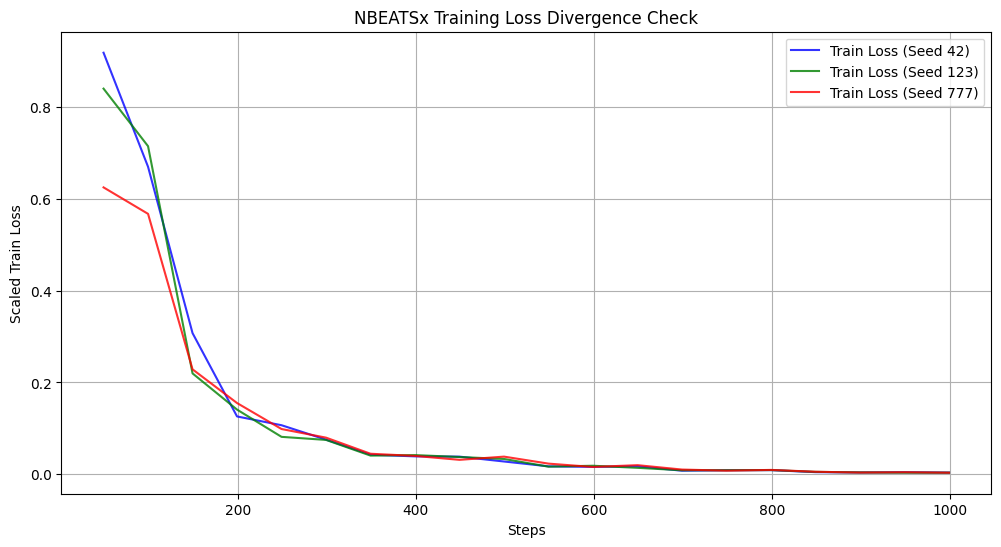

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pytorch_lightning.loggers import CSVLogger
from neuralforecast import NeuralForecast
from neuralforecast.models import NBEATSx
import glob

print("=== NBEATSx DEEP DIVE (SEED & LOSS CHECK) ===")

seeds = [42, 123, 777]
nan_counts = {}
metrics_paths = {}

for s in seeds:
    print(f"\nTraining NBEATSx dengan Seed={s}...")
    logger = CSVLogger(save_dir='/kaggle/working/logs', name=f'NBEATSx_Check_Seed_{s}')
    
    # 1. Inisiasi model terisolasi
    nbeats_test = NBEATSx(
        h=H, input_size=INPUT_SIZE, hist_exog_list=exog_cols, 
        max_steps=MAX_STEPS, val_check_steps=50, random_seed=s, 
        scaler_type='standard'
    )
    nbeats_test.trainer_kwargs = {'logger': logger, 'enable_checkpointing': False, 'devices': 1}
    
    nf_test = NeuralForecast(models=[nbeats_test], freq='D')
    
    # 2. Training (Ingat membuang real_date agar tidak crash)
    nf_test.fit(df=df_train.drop(columns=['real_date']), val_size=n_val)
    
    # 3. Prediksi dan Cek NaN
    preds = nf_test.predict(df=df_train.drop(columns=['real_date']))
    nan_count = preds['NBEATSx'].isna().sum()
    inf_count = np.isinf(preds['NBEATSx']).sum()
    nan_counts[s] = {'NaN': nan_count, 'Inf': inf_count}
    print(f"-> Seed {s} | NaN: {nan_count} | Inf: {inf_count} | Rata-rata Prediksi: {preds['NBEATSx'].mean():.6f}")
    
    # 4. Ambil log metrics
    log_files = glob.glob(f'/kaggle/working/logs/NBEATSx_Check_Seed_{s}/*/metrics.csv')
    if log_files:
        metrics_paths[s] = log_files[-1]

# Plot Training Curves untuk semua Seed
plt.figure(figsize=(12, 6))
colors = {42: 'blue', 123: 'green', 777: 'red'}

for s, path in metrics_paths.items():
    m_df = pd.read_csv(path)
    train_col = 'train_loss_step' if 'train_loss_step' in m_df.columns else 'train_loss_epoch'
    train_loss = m_df[['step', train_col]].dropna().groupby('step').mean()
    plt.plot(train_loss.index, train_loss[train_col], label=f'Train Loss (Seed {s})', color=colors[s], alpha=0.8)

plt.title('NBEATSx Training Loss Divergence Check')
plt.xlabel('Steps')
plt.ylabel('Scaled Train Loss')
plt.legend()
plt.grid(True)
plt.show()
